# NIC ICE CREAM : Sales Prediction

## Objective
To predict the sales value of NIC ice creams (`Sales_INR`) from price, discount, weather, footfall, advertising, city and product category, using linear regression on a simulated dataset of 3,000 records.

`Data source`: Real sales data for NIC Ice Creams is not publicly available, so this project uses a simulated dataset of 3,000 records generated with Claude, based on NIC's product categories and pricing. The sales figures are simulated and do not represent NIC's actual sales.

## 1. Import Libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

## 2. Load the Dataset

In [35]:
df = pd.read_csv("NIC_Ice_Creams_Simulated_Sales_3000.csv")
df.head()

,Date,City,Product,Category,Pack_Size,List_Price_INR,Discount_Percent,Selling_Price_INR,Temperature_C,Rainfall_mm,Weather,Day_Type,Footfall,Advertising_Spend_INR,Units_Sold,Sales_INR
0,2025-01-01,Mangaluru,Tender Coconut,Fruit N Nut,500ml,350,15.0,297.50,20.0,4.4,Cloudy,Weekday,53,1123.51,47,13982.5
1,2025-01-01,Bengaluru,Macadamia Nuts,Super Premium,500ml,475,5.0,451.25,28.5,0.0,Clear,Weekday,68,998.60,42,18952.5
2,2025-01-01,Kolkata,Roasted Almond (No Added Sugar),No Added Sugar,500ml,400,10.0,360.00,20.1,1.4,Clear,Weekday,38,941.67,22,7920.0
3,2025-01-01,Mangaluru,Jaggery Almond,Indian Inspirations,500ml,375,0.0,375.00,23.9,0.7,Clear,Weekday,64,1172.96,35,13125.0
4,2025-01-01,Chennai,Gajar Halwa,Indian Inspirations,500ml,375,0.0,375.00,23.4,0.4,Clear,Weekday,69,824.06,39,14625.0


In [4]:
df.shape

(3000, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   3000 non-null   object 
 1   City                   3000 non-null   object 
 2   Product                3000 non-null   object 
 3   Category               3000 non-null   object 
 4   Pack_Size              3000 non-null   object 
 5   List_Price_INR         3000 non-null   int64  
 6   Discount_Percent       2970 non-null   float64
 7   Selling_Price_INR      3000 non-null   float64
 8   Temperature_C          3000 non-null   float64
 9   Rainfall_mm            2970 non-null   float64
 10  Weather                3000 non-null   object 
 11  Day_Type               3000 non-null   object 
 12  Footfall               3000 non-null   int64  
 13  Advertising_Spend_INR  2970 non-null   float64
 14  Units_Sold             3000 non-null   int64  
 15  Sale

In [6]:
df.describe(include = "all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,3000,605,2026-07-24,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,3000,10,Mangaluru,328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,3000,27,Madagascar Chocolate,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3000,6,Fruit N Nut,686,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pack_Size,3000,1,500ml,3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
List_Price_INR,3000.0,NaN,NaN,NaN,390.733333,37.721831,350.0,350.0,375.0,400.0,475.0
Discount_Percent,2970.0,NaN,NaN,NaN,7.254209,5.879475,0.0,0.0,5.0,10.0,20.0
Selling_Price_INR,3000.0,NaN,NaN,NaN,362.420417,42.332179,280.0,332.5,356.25,382.5,475.0
Temperature_C,3000.0,NaN,NaN,NaN,27.8177,4.013372,15.6,24.8,28.1,30.9,38.2
Rainfall_mm,2970.0,NaN,NaN,NaN,3.055657,4.281013,0.0,0.5,1.5,3.8,34.2


In [7]:
# Data quality check

In [8]:
df.isnull().sum()

Date                      0
City                      0
Product                   0
Category                  0
Pack_Size                 0
List_Price_INR            0
Discount_Percent         30
Selling_Price_INR         0
Temperature_C             0
Rainfall_mm              30
Weather                   0
Day_Type                  0
Footfall                  0
Advertising_Spend_INR    30
Units_Sold                0
Sales_INR                 0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

Date                      object
City                      object
Product                   object
Category                  object
Pack_Size                 object
List_Price_INR             int64
Discount_Percent         float64
Selling_Price_INR        float64
Temperature_C            float64
Rainfall_mm              float64
Weather                   object
Day_Type                  object
Footfall                   int64
Advertising_Spend_INR    float64
Units_Sold                 int64
Sales_INR                float64
dtype: object

In [11]:
df["City"].value_counts()

City
Mangaluru    328
Jaipur       322
Mumbai       320
Kolkata      308
Pune         297
Chennai      291
Gurugram     289
Bengaluru    288
Hyderabad    279
Delhi NCR    278
Name: count, dtype: int64

In [12]:
df["Product"].value_counts()

Product
Madagascar Chocolate                  129
Coffee Walnut                         128
Anjeer (No Added Sugar)               127
French Vanilla                        121
Mixed Berries                         121
Anjeer                                121
Macadamia Nuts                        120
Gulab Jamun                           120
Choco Chips                           119
Tender Coconut                        118
Dry Fruit Overload                    118
Alphonso Mango                        116
Strawberry                            113
Lychee                                112
Strawberry Cheesecake                 111
Gajar Halwa                           109
Sea Salt Caramel                      108
Alphonso Mango (No Added Sugar)       108
Sitaphal                              106
Jaggery Almond                        102
Belgian Chocolate (No Added Sugar)    101
Belgian Chocolate                     101
Mishti Doi                             99
Velvety Nutella           

In [13]:
df["Category"].value_counts()

Category
Fruit N Nut                  686
Super Premium                569
No Added Sugar               519
Speciality                   458
Indian Inspirations          430
International Inspiration    338
Name: count, dtype: int64

In [14]:
df["Weather"].value_counts()

Weather
Clear     2085
Cloudy     617
Rainy      298
Name: count, dtype: int64

In [15]:
df["Day_Type"].value_counts()

Day_Type
Weekday    2190
Weekend     810
Name: count, dtype: int64

In [34]:
df["Pack_Size"].value_counts()

Pack_Size
500ml    3000
Name: count, dtype: int64

In [33]:
df[["List_Price_INR","Discount_Percent","Selling_Price_INR","Temperature_C","Footfall","Advertising_Spend_INR","Units_Sold","Sales_INR"]].describe()

,List_Price_INR,Discount_Percent,Selling_Price_INR,Temperature_C,Footfall,Advertising_Spend_INR,Units_Sold,Sales_INR
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,390.733333,7.231667,362.420417,27.817700,74.375667,1102.595400,44.711333,16061.152083
std,37.721831,5.854294,42.332179,4.013372,15.643639,262.154389,11.385805,4016.508844
min,350.000000,0.000000,280.000000,15.600000,20.000000,217.320000,10.000000,4000.000000
25%,350.000000,0.000000,332.500000,24.800000,64.000000,927.235000,37.000000,13300.000000
50%,375.000000,5.000000,356.250000,28.100000,74.000000,1098.300000,45.000000,15960.000000
75%,400.000000,10.000000,382.500000,30.900000,85.000000,1272.210000,52.000000,18620.000000
max,475.000000,20.000000,475.000000,38.200000,127.000000,2013.270000,83.000000,29970.000000


## Observation
- Discount_Percent has 30 missing values.
- Rainfall_mm has 30 missing values.
- Advertising_Spent_INR has 30 missing values.

## 3. Data cleaning

In [17]:
# filling missing values
df["Discount_Percent"] = df["Discount_Percent"].fillna(df["Discount_Percent"].median())
df["Rainfall_mm"] = df["Rainfall_mm"].fillna(df["Rainfall_mm"].median())
df["Advertising_Spend_INR"] = df["Advertising_Spend_INR"].fillna(df["Advertising_Spend_INR"].median())

In [18]:
df.isnull().sum()

Date                     0
City                     0
Product                  0
Category                 0
Pack_Size                0
List_Price_INR           0
Discount_Percent         0
Selling_Price_INR        0
Temperature_C            0
Rainfall_mm              0
Weather                  0
Day_Type                 0
Footfall                 0
Advertising_Spend_INR    0
Units_Sold               0
Sales_INR                0
dtype: int64

## 4. EDA

### Distribution of Sales

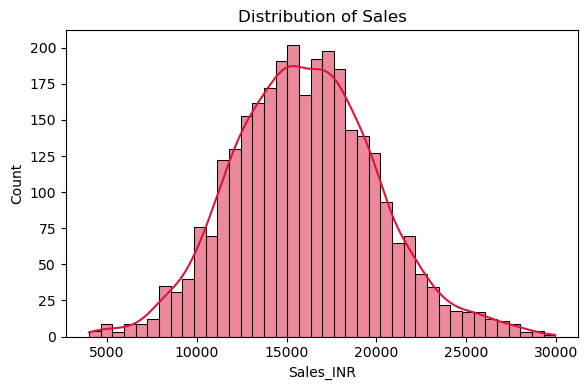

In [19]:
plt.figure(figsize = (6,4))
sns.histplot(df["Sales_INR"], bins = 40, kde = True, color = "crimson")
plt.title("Distribution of Sales")
plt.xlabel("Sales_INR")
plt.tight_layout()
plt.show()

## Observation
- The graph is bell-shaped and nearly symmetric, so sales are evenly spread with no extreme outliers.
- Sales are mostly between ₹12,000 and ₹20,000, with the highest count around ₹15,000 to ₹17,500.

### How often does NIC give discounts, and how big are they?

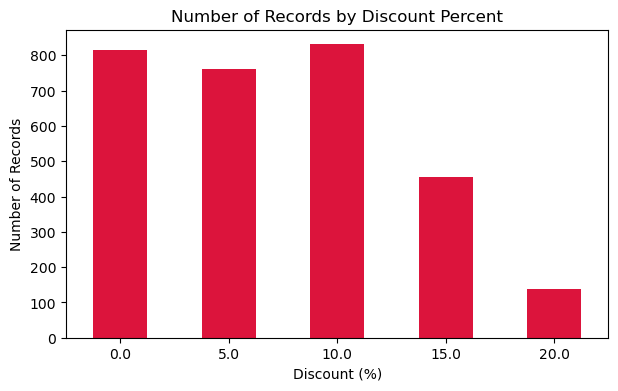

Discount_Percent
0.0     27.2
5.0     25.3
10.0    27.7
15.0    15.2
20.0     4.6
Name: count, dtype: float64


In [20]:
discount_counts = df["Discount_Percent"].value_counts().sort_index()
discount_counts.plot(kind = "bar",figsize = (7,4), color = "crimson", rot = 0)
plt.title("Number of Records by Discount Percent")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Records")
plt.show()   

discount_percentages = discount_counts / len(df) * 100
print(discount_percentages.round(1))

### Observation
- Discounts are used on most sales. 10% is the most common (27.7%), followed closely by 0% (27.2%) and 5% (25.3%).
- Larger discounts are less common: 15% is about 15% of records and 20% only about 5%.

### Do sales go up when it gets hotter?

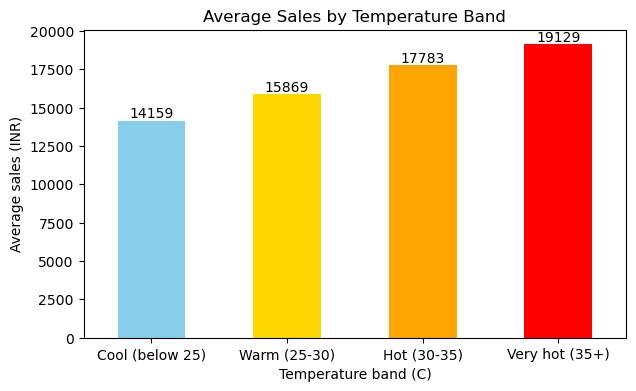

Records in each band:
Temperature_C
Cool (below 25)     816
Warm (25-30)       1194
Hot (30-35)         933
Very hot (35+)       57
Name: count, dtype: int64


In [21]:
temp_band = pd.cut(
    df["Temperature_C"],
    bins=[0, 25, 30, 35, 50],
    labels=["Cool (below 25)", "Warm (25-30)", "Hot (30-35)", "Very hot (35+)"]
)
avg_sales = df.groupby(temp_band, observed=True)["Sales_INR"].mean()

ax = avg_sales.plot(
    kind="bar",
    figsize=(7, 4),
    color=["skyblue", "gold", "orange", "red"],
    rot=0
)

ax.bar_label(ax.containers[0], fmt="%.0f")

plt.title("Average Sales by Temperature Band")
plt.xlabel("Temperature band (C)")
plt.ylabel("Average sales (INR)")
plt.show()

print("Records in each band:")
print(temp_band.value_counts().sort_index())

### Observation
- Sales go up as the weather gets hotter. Average sales climb from about ₹14,200 on cool days to about ₹19,100 on very hot days.
- This is an increase of roughly ₹5,000. The "very hot" band has only 57 records, so that last bar is less reliable.

###  Which product category earns the most?

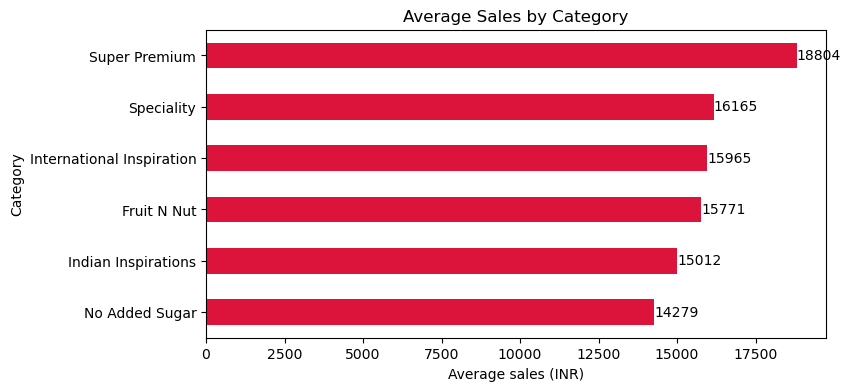

In [22]:
category_sales = df.groupby("Category")["Sales_INR"].mean()
category_sales = category_sales.sort_values()

ax = category_sales.plot(kind="barh", figsize=(8, 4), color="crimson")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Average Sales by Category")
plt.xlabel("Average sales (INR)")
plt.show()

### Observation
- Super Premium earns the highest, with average sales of about ₹18,800, while No Added Sugar is the lowest at about ₹14,300.
- The remaining four categories average between ₹15,000 and ₹16,200, so their sales are fairly similar.

## 5. Data Preprocessing: Feature Selection and Encoding

In [23]:
data = df.drop(columns = ["Units_Sold", "Selling_Price_INR", "Date", "Product", "Pack_Size"])

data = pd.get_dummies(data, drop_first = True)

print("Shape:", data.shape)
data.head()

Shape: (3000, 24)


,List_Price_INR,Discount_Percent,Temperature_C,Rainfall_mm,Footfall,Advertising_Spend_INR,Sales_INR,City_Chennai,City_Delhi NCR,City_Gurugram,...,City_Mumbai,City_Pune,Category_Indian Inspirations,Category_International Inspiration,Category_No Added Sugar,Category_Speciality,Category_Super Premium,Weather_Cloudy,Weather_Rainy,Day_Type_Weekend
0,350,15.0,20.0,4.4,53,1123.51,13982.5,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,475,5.0,28.5,0.0,68,998.60,18952.5,False,False,False,...,False,False,False,False,False,False,True,False,False,False
2,400,10.0,20.1,1.4,38,941.67,7920.0,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,375,0.0,23.9,0.7,64,1172.96,13125.0,False,False,False,...,False,False,True,False,False,False,False,False,False,False
4,375,0.0,23.4,0.4,69,824.06,14625.0,True,False,False,...,False,False,True,False,False,False,False,False,False,False


In [24]:
X = data.drop(columns = "Sales_INR")
y = data["Sales_INR"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2400
Testing rows: 600


In [25]:
model = LinearRegression()

In [26]:
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
y_pred = model.predict(X_test)

## 6. Model Evaluation

In [28]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))

print("r2_score:", round(r2,2))
print("MAE:", round(mae,2))
print("RMSE:", round(rmse,2))

r2_score: 0.51
MAE: 2188.35
RMSE: 2738.81


## 7. Actual vs Predicted

In [29]:
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,12825.0,12776.315907
1,17340.0,14715.191231
2,18360.0,17280.490654
3,13965.0,13895.422870
4,18742.5,19898.467341
5,18750.0,15525.745742
6,11250.0,15201.230701
7,18240.0,15642.305124
8,18225.0,16651.320671
9,19125.0,19584.936395


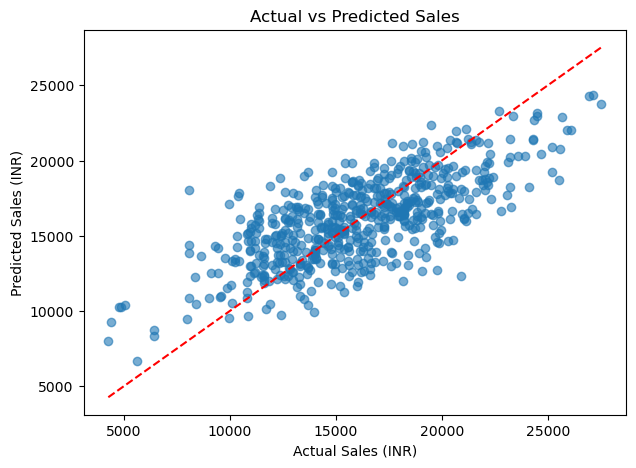

In [30]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Sales (INR)")
plt.ylabel("Predicted Sales (INR)")
plt.title("Actual vs Predicted Sales")
plt.show()

In [31]:
print("Intercept:", round(model.intercept_,2))

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_})
coefficients = coefficients.sort_values("Coefficient",ascending = False)

coefficients

Intercept: 2667.83


,Feature,Coefficient
19,Category_Super Premium,3121.647224
22,Day_Type_Weekend,1302.547934
13,City_Mumbai,278.698133
2,Temperature_C,259.877872
18,Category_Speciality,213.187514
16,Category_International Inspiration,83.455382
4,Footfall,72.962670
8,City_Gurugram,40.729938
1,Discount_Percent,11.335992
5,Advertising_Spend_INR,1.061705


### Observation 
- Each coefficient shows how much sales change when that feature changes, with everything else held the same. The intercept (₹2,668) is just the starting point of the equation, not a real prediction.
- Sales go up with the Super Premium category (+₹3,122 vs Fruit N Nut), weekends (+₹1,303 vs weekdays), higher temperature (+₹260 per °C) and more footfall (+₹73 per customer).
- Sales go down in Mangaluru (−₹2,482) and Kolkata (−₹1,797) compared with Bengaluru, for No Added Sugar (−₹1,473) and on rainy days (−₹424). Discount and advertising have only a small effect.

## Conclusion

EDA

- Hotter weather means higher sales: average sales rise from about ₹14,200 on cool days to about ₹19,100 on very hot days.
- Super Premium earns the most (about ₹18,800) and No Added Sugar the least (about ₹14,300).


ML

- The linear regression model gives R² = 0.51 and MAE ≈ ₹2,188 (about 14% of average sales), so it explains about half of the variation in sales.
- The biggest drivers of sales are product category (Super Premium), weekends, temperature and footfall, while discount and advertising matter little.
- Location and weather also matter: Mangaluru (−₹2,482) and Kolkata (−₹1,797) sell noticeably less than Bengaluru, and rainy days sell about ₹424 less than clear days.


Limitations

- The dataset is simulated (generated with Claude), so the findings describe the simulation and not NIC's real sales.
- R² is only 0.51, so about half of the variation is unexplained, and the model over-predicts low sales and under-predicts high sales.